In [1]:
import math
import elapid as ela
import pandas as pd
import seaborn as sns
import rasterio as rio
import geopandas as gpd
import config
import matplotlib.colors as mcolors


from rasterio.warp import reproject, Resampling
import numpy as np
import pathlib
import os
from scipy.stats import ks_2samp
from maxent_insect_dir import config

import matplotlib.pyplot as plt
plt.style.use('my_style.mplstyle')

## Load data

In [38]:
# US boundary
US_boundary = gpd.read_file(config.PATH_TO_US_BOUNDARY)
# Insect_name
INSECT= 'Spooted_Lanternfly'
# Base path to saved results
BASE_PATH = config.PATH_TO_SAVE_RESULTS
# Pathway
PATHWAY = 'SSP_245'
# Features used
FEATURE = 'lph'
# Beta multiplier
BETA = '1.5'
# Mixing coeff
MIXING_COEFF = '0.25'
# Save tag
SAVE_TAG = f"cuurent_future_predictions_{INSECT}_new_fig.pdf"

In [39]:
path = os.path.join(BASE_PATH,PATHWAY,INSECT,MIXING_COEFF,FEATURE,BETA)
experiment = os.listdir(path)[0]

# Plot currennt and future projection

In [40]:
tiff_files = ['current.tif','2040.tif','2060.tif']

In [41]:
def plot_projection(projection, tag, plot=False, save_path=False):
    # Plot the suitability predictions
    fig, ax = plt.subplots(1, 1, figsize=(10, 4), dpi=100)
    vmin = np.min(projection.ravel())
    vmax = np.max(projection.ravel())
    img = ax.imshow(projection, vmin=vmin, vmax=vmax, cmap='coolwarm')
    ax.set_title(tag)
    ax.set_xticks([])
    ax.set_yticks([])
    fig.colorbar(img, ax=ax, label="relative occurrence probability", pad=0.04)
    
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path)
    if plot:
        plt.show()
    plt.close(fig)

In [42]:
# # --- Custom Colormap ---
# cmap = mcolors.LinearSegmentedColormap.from_list(
#     "custom_gradient",
#     [
#         (0.0,  "white"),   # low end
#         (0.15, "grey"),
#         (0.3,  "yellow"),
#         (0.5,  "orange"),
#         (0.7,  "red"),
#         (1.0,  "darkred")  # optional: deeper red for top end
#     ]
# )

# # --- Load raster arrays + metadata ---
# arrays = []
# for f in tiff_files:
#     path_ = os.path.join(path, experiment, f)
#     with rio.open(path_) as src:
#         arr = src.read(1).astype(float)
#         arr[arr == -9999] = np.nan   # handle NoData
#         arrays.append((arr, src.transform))
#         crs = src.crs   # CRS of rasters (assume all the same)

# # --- Global min/max (for consistent color scaling) ---
# vmin = min(np.nanmin(arr) for arr, _ in arrays)
# vmax = max(np.nanmax(arr) for arr, _ in arrays)

# # --- Plotting ---
# fig, axes = plt.subplots(1, len(arrays), figsize=(10, 10))

# for ax, (arr, transform) in zip(axes, arrays):
#     # Raster plotted with spatial extent from transform
#     im = ax.imshow(
#         arr,
#         cmap=cmap,
#         vmin=vmin,
#         vmax=vmax,
#         extent=(
#             transform[2],                          # xmin
#             transform[2] + transform[0] * arr.shape[1],  # xmax
#             transform[5] + transform[4] * arr.shape[0],  # ymin
#             transform[5]                           # ymax
#         )
#     )
    
#     # Overlay US boundary (reprojected to raster CRS)
#     US_boundary.to_crs(crs).plot(
#         ax=ax,
#         color="none",
#         edgecolor="black",
#         linewidth=0.8
#     )
    
#     ax.axis("off")

# # --- Adjust layout to make room for colorbar ---
# fig.subplots_adjust(right=0.95)

# # # --- Add vertical colorbar on the right (70–80% of height) ---
# # # [x0, y0, width, height] are in figure coordinates (0–1)
# # cbar = fig.colorbar(im, ax=axes, shrink=0.3, aspect=25, pad=0.05, orientation="vertical")

# # --- Add vertical colorbar on the right side of the figure ---
# # Coordinates in figure space: [left, bottom, width, height]
# cax = fig.add_axes([0.95, 0.45, 0.005, 0.1])  # tweak bottom/height as needed

# # Add the colorbar to that axis
# cbar = fig.colorbar(im, cax=cax)

# # plt.show()

# # plt.tight_layout()
# plt.show()


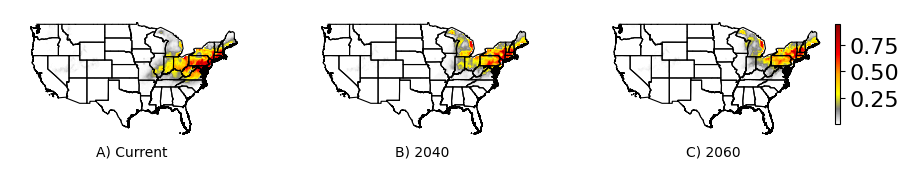

In [43]:
# --- Custom Colormap ---
cmap = mcolors.LinearSegmentedColormap.from_list(
    "custom_gradient",
    [
        (0.0,  "white"),   # low end
        (0.15, "grey"),
        (0.3,  "yellow"),
        (0.5,  "orange"),
        (0.7,  "red"),
        (1.0,  "darkred")  # optional: deeper red for top end
    ]
)

# --- Load raster arrays + metadata ---
arrays = []
for f in tiff_files:
    path_ = os.path.join(path, experiment, f)
    with rio.open(path_) as src:
        arr = src.read(1).astype(float)
        arr[arr == -9999] = np.nan   # handle NoData
        arrays.append((arr, src.transform))
        crs = src.crs   # CRS of rasters (assume all the same)

# --- Global min/max (for consistent color scaling) ---
vmin = min(np.nanmin(arr) for arr, _ in arrays)
vmax = max(np.nanmax(arr) for arr, _ in arrays)


# --- Plotting ---
fig, axes = plt.subplots(1, len(arrays), figsize=(10, 10))

# Define the labels you want
subplot_labels = ["A) Current", "B) 2040", "C) 2060"]

# Coordinates for the bottom label:
# x=0.5 (center of the x-axis)
# y=-0.05 (just below the plotting area; adjust this value if needed)
label_y_position = -0.05 

for i, (ax, (arr, transform)) in enumerate(zip(axes, arrays)):
    
    # Raster plotted with spatial extent from transform
    im = ax.imshow(
        arr,
        cmap=cmap,
        vmin=vmin,
        vmax=vmax,
        extent=(
            transform[2],                             # xmin
            transform[2] + transform[0] * arr.shape[1],  # xmax
            transform[5] + transform[4] * arr.shape[0],  # ymin
            transform[5]                                # ymax
        )
    )
    
    # Overlay US boundary (reprojected to raster CRS)
    US_boundary.to_crs(crs).plot(
        ax=ax,
        color="none",
        edgecolor="black",
        linewidth=0.8
    )
    
    ax.axis("off")
    
    # --- ADD THE LABEL TO THE BOTTOM ---
    if i < len(subplot_labels):
        ax.text(
            0.5,                               # x-coordinate (0.5 is the center)
            label_y_position,                  # y-coordinate (just below the axis)
            subplot_labels[i],                 # The label text
            transform=ax.transAxes,            # Key: Use axis coordinates (0 to 1)
            ha='center',                       # Horizontal alignment: centered on x=0.5
        )

# --- Adjust layout to make room for colorbar ---
fig.subplots_adjust(right=0.95)

# --- Add vertical colorbar on the right side of the figure ---
# Coordinates in figure space: [left, bottom, width, height]
cax = fig.add_axes([0.95, 0.45, 0.005, 0.1])    # tweak bottom/height as needed

# Add the colorbar to that axis
cbar = fig.colorbar(im, cax=cax)
plt.savefig(os.path.join(config.save_images, SAVE_TAG), bbox_inches='tight')
plt.show()